In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from plotting import *
from HeteroBilayer import HeteroBilayer
import utils
import analytic_metric

In [3]:
plt.rcParams.update({
    'figure.figsize': (7, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': False,   # remove top/right borders
    'axes.spines.right': False,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

# Triangular lattice

### Shifting Wannier functions

In [4]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=40, V=6.6, n_shells=8)

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\mathbf{a}_2$')

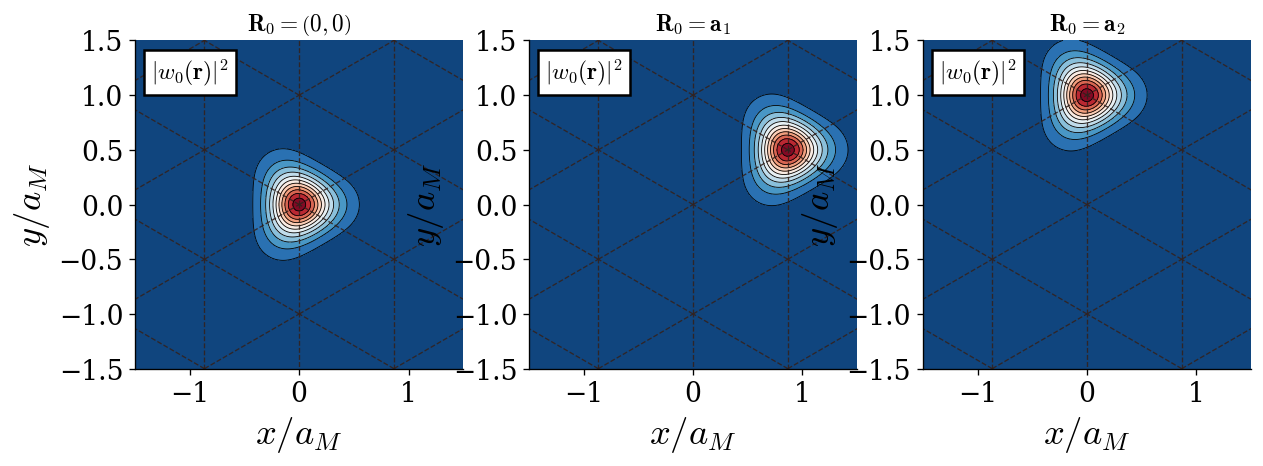

In [5]:
scale = 1.5
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(1, 3, figsize=(12, 8))

im = plot_wannier_function(sys, ax[0], X, Y, cmap='RdBu_r')
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

im = plot_wannier_function(sys, ax[1], X, Y, R0=sys.a1)
ax[1].set_title(r"$\mathbf{R}_0 = \mathbf{a}_1$")

im = plot_wannier_function(sys, ax[2], X, Y, R0=sys.a2)
ax[2].set_title(r"$\mathbf{R}_0 = \mathbf{a}_2$")

### Hopping integrals

In [6]:
sys = HeteroBilayer()
thetas = np.linspace(0.5, 3.0, 10)
t1 = []
t2 = []
t3 = []
t1_kspace = []
t2_kspace = []
t3_kspace = []

for th in tqdm(thetas):
    sys.theta_deg = th

    hoppings = sys.hopping_1band(orders=[1, 2, 3])
    hoppings_kspace = sys.hopping_1band_kspace(orders=[1, 2, 3])
    
    
    t1_kspace.append(hoppings_kspace[0])
    t2_kspace.append(hoppings_kspace[1])
    t3_kspace.append(hoppings_kspace[2])
    t1.append(hoppings[0])
    t2.append(hoppings[1])
    t3.append(hoppings[2])

100%|██████████| 10/10 [02:52<00:00, 17.21s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


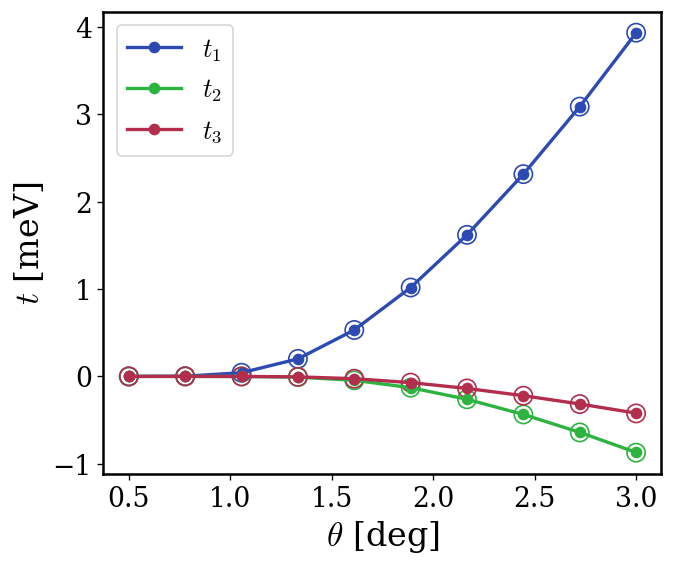

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, t1, marker="o", label=r"$t_1$", color=cols[0])
ax.scatter(thetas, t1_kspace, marker="o", edgecolors=cols[0], facecolors="none", s=120)
ax.plot(thetas, t2, marker="o", label=r"$t_2$", color=cols[1])
ax.scatter(thetas, t2_kspace, marker="o", edgecolors=cols[1], facecolors="none", s=120)
ax.plot(thetas, t3, marker="o", label=r"$t_3$", color=cols[2])
ax.scatter(thetas, t3_kspace, marker="o", edgecolors=cols[2], facecolors="none", s=120)
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Coulomb interactions

In [8]:
thetas = np.linspace(0.5, 3.0, 10)
U0 = []
U1 = []
U2 = []
U0_kspace = []
U1_kspace = []
U2_kspace = []

for th in tqdm(thetas):
    sys.theta_deg = th

    interactions = sys.interaction_1band(orders=[0, 1, 2])
    interactions_kspace = sys.interaction_1band_kspace(orders=[0, 1, 2])

    # Coulomb matrix elements in eV
    U0.append(sys.epsilon * interactions[0] / 1000)
    U1.append(sys.epsilon * interactions[1] / 1000)
    U2.append(sys.epsilon * interactions[2] / 1000)
    U0_kspace.append(sys.epsilon * interactions_kspace[0] / 1000)
    U1_kspace.append(sys.epsilon * interactions_kspace[1] / 1000)
    U2_kspace.append(sys.epsilon * interactions_kspace[2] / 1000)

100%|██████████| 10/10 [01:56<00:00, 11.68s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


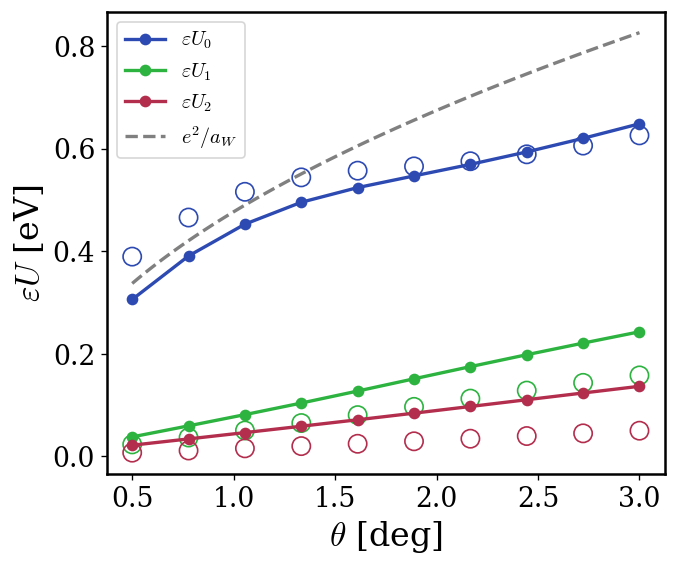

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, U0, marker="o", label=r"$\varepsilon U_0$", color=cols[0])
ax.scatter(thetas, U0_kspace, marker="o", edgecolors=cols[0], facecolors="none", s=120)
ax.plot(thetas, U1, marker="o", label=r"$\varepsilon U_1$", color=cols[1])
ax.scatter(thetas, U1_kspace, marker="o", edgecolors=cols[1], facecolors="none", s=120)
ax.plot(thetas, U2, marker="o", label=r"$\varepsilon U_2$", color=cols[2])
ax.scatter(thetas, U2_kspace, marker="o", edgecolors=cols[2], facecolors="none", s=120)

tt = np.linspace(0.5, 3.0, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))
ax.plot(tt, sys.E_SQUARED / (utils.spread_harmonic_approx(aMs, sys.V, sys.psi) * 1000),
       color="gray", linestyle="--", label=r"$e^2/a_W$", linewidth=2)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon U$ [eV]", fontsize=20)
ax.legend(fontsize=12)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Exchange interaction

In [10]:
thetas = np.linspace(0.5, 3.0, 10)
X = []

for th in tqdm(thetas):
    sys.theta_deg = th

    interactions = sys.exchange_1band(orders=[1])

    # Coulomb matrix elements in meV
    X.append(sys.epsilon * interactions[0])

100%|██████████| 10/10 [00:47<00:00,  4.79s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


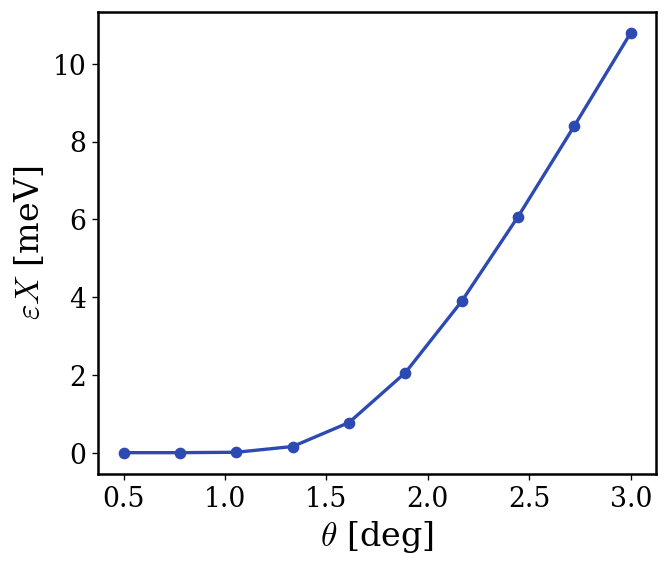

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, X, marker="o", label=r"$\varepsilon X$", color=cols[0])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon X$ [meV]", fontsize=20)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

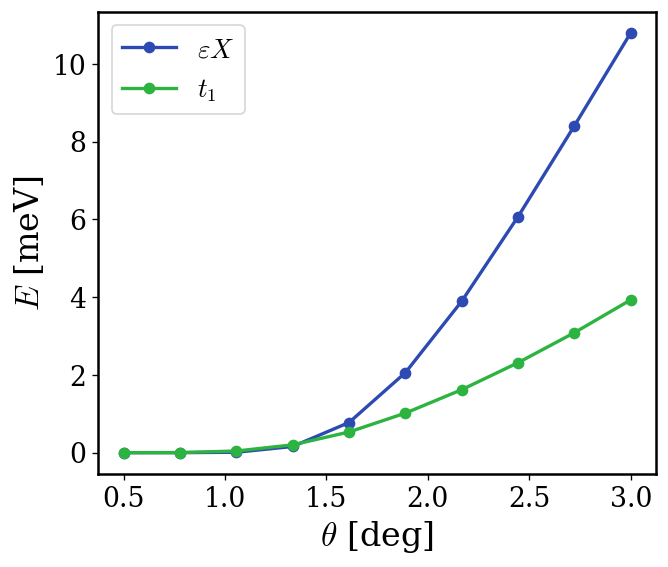

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, X, marker="o", label=r"$\varepsilon X$", color=cols[0])
ax.plot(thetas, t1, marker="o", label=r"$t_1$", color=cols[1])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$E$ [meV]", fontsize=20)
ax.legend(fontsize=16)
# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

### Phase diagrams
### $(\theta,V)$

In [15]:
sys = HeteroBilayer(epsilon=18, psi_deg=40)

THETA_MIN = 1.0
THETA_MAX = 3.0
THETA_POINTS = 10

V_MIN = 4.0
V_MAX = 12.0
V_POINTS = 10

thetas = np.linspace(THETA_MIN, THETA_MAX, THETA_POINTS)
V_vals = np.linspace(V_MIN, V_MAX, V_POINTS)

Thetamesh, Vmesh = np.meshgrid(thetas, V_vals)

J_v_theta = np.zeros((len(V_vals), len(thetas)))

for i, V in tqdm(enumerate(V_vals), total=len(V_vals)):
    sys.V = V
    for j, theta in enumerate(thetas):
        sys.theta_deg = theta
        J_v_theta[i, j] = sys.spin_coupling_1band()

100%|██████████| 10/10 [13:01<00:00, 78.11s/it]


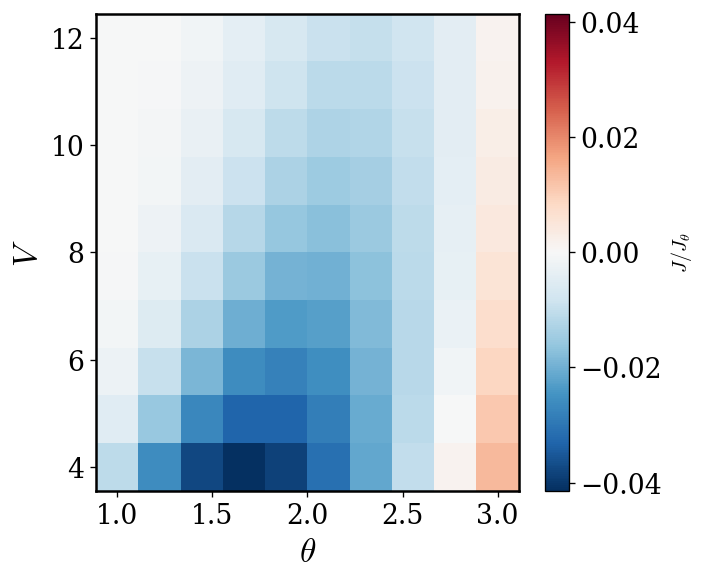

In [17]:
J_max = np.max(np.abs(J_v_theta))

plt.figure(figsize=(6, 5))

pcm = plt.pcolormesh(
    Thetamesh, Vmesh, J_v_theta,
    shading="auto",
    cmap="RdBu_r",
    vmin=-J_max,
    vmax=J_max,
)

plt.colorbar(pcm, label=r"$J / J_\theta$")
plt.xlabel(r"$\theta$", fontsize=20)
plt.ylabel(r"$V$", fontsize=20)

# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.tight_layout()
plt.show()

### $(\theta,\varepsilon^{-1})$

In [18]:
sys = HeteroBilayer(psi_deg=40)

THETA_MIN = 0.5
THETA_MAX = 1.5
THETA_POINTS = 10

EPS_MIN = 0.04
EPS_MAX = 0.1
EPS_POINTS = 10

thetas = np.linspace(THETA_MIN, THETA_MAX, THETA_POINTS)
inv_epsilon = np.linspace(EPS_MIN, EPS_MAX, EPS_POINTS)

Thetamesh, Eps_mesh = np.meshgrid(thetas, inv_epsilon)

J_eps_theta = np.zeros((len(inv_epsilon), len(thetas)))

for i, ie in tqdm(enumerate(inv_epsilon), total=len(inv_epsilon)):
    sys.epsilon = 1 / ie
    for j, theta in enumerate(thetas):
        sys.theta_deg = theta
        J_eps_theta[i, j] = sys.spin_coupling_1band()

100%|██████████| 10/10 [12:17<00:00, 73.72s/it]


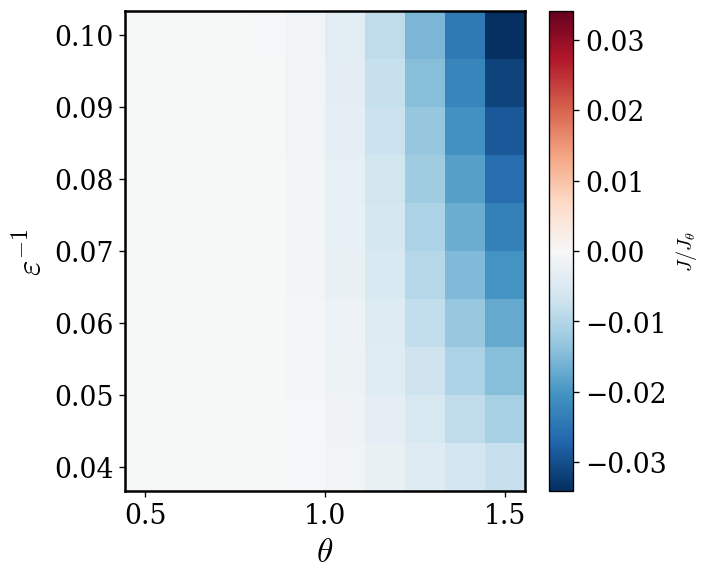

In [19]:
J_max = np.max(np.abs(J_eps_theta))

plt.figure(figsize=(6, 5))

pcm = plt.pcolormesh(
    Thetamesh, Eps_mesh, J_eps_theta,
    shading="auto",
    cmap="RdBu_r",
    vmin=-J_max,
    vmax=J_max,
)

plt.colorbar(pcm, label=r"$J / J_\theta$")
plt.xlabel(r"$\theta$", fontsize=20)
plt.ylabel(r"$\varepsilon^{-1}$", fontsize=20)

# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.tight_layout()
plt.show()

### $(V,\varepsilon^{-1})$

In [ ]:
sys = HeteroBilayer(theta_deg=2.5)

V_MIN = 4.0
V_MAX = 12.0
V_POINTS = 10

EPS_MIN = 0.04
EPS_MAX = 0.1
EPS_POINTS = 10

V_vals = np.linspace(V_MIN, V_MAX, V_POINTS)
inv_epsilon = np.linspace(EPS_MIN, EPS_MAX, EPS_POINTS)

Vmesh, Eps_mesh = np.meshgrid(V_vals, inv_epsilon)

J_eps_v = np.zeros((len(inv_epsilon), len(V_vals)))

for i, ie in tqdm(enumerate(inv_epsilon), total=len(inv_epsilon)):
    sys.epsilon = 1 / ie
    for j, v in enumerate(V_vals):
        sys.V = v
        J_eps_v[i, j] = sys.spin_coupling_1band()

In [ ]:
J_max = np.max(np.abs(J_eps_v))

plt.figure(figsize=(6, 5))

pcm = plt.pcolormesh(
    Vmesh, Eps_mesh, J_eps_v,
    shading="gouraud",
    cmap="RdBu_r",
    vmin=-J_max,
    vmax=J_max,
)

plt.colorbar(pcm, label=r"$J / J_\theta$")
plt.xlabel(r"$V$ [meV]", fontsize=20)
plt.ylabel(r"$\varepsilon^{-1}$", fontsize=20)

# Add box around the plot
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.tight_layout()
plt.show()